# Analysis AI-Team

### Load and import 

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------------------
# from pair_a.<file> import ...  


print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()
    
# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

/home/mut/projects/AI4VIS/ai_and_visualisation_OpenSI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 4070 Ti SUPER
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


## Q2: Overconfidence and training coverage
When is the model confidently wrong, and can we infer which countries were in its Street View training?

In [2]:
from pair_a import q2_confidence as q2, viz

countries = mapper.table
clip_preds = pd.read_parquet("results/shared/clip_v1_center_crop/predictions.parquet")   # original CLIP

### Q2.1 Calibration
- Is the top-1 probability an honest estimate of the accuracy?
- StreetCLIP vs. original CLIP (same model before the Street View fine-tuning)
- Lower panel: how many images are behind each point

,Images,Mean confidence,Accuracy,95 % CI
0% to 10%,"1,899",8.1 %,6.6 %,5.6 to 7.8 %
10% to 20%,"19,357",15.9 %,11.8 %,11.4 to 12.3 %
20% to 30%,"29,053",25.0 %,19.8 %,19.4 to 20.3 %
30% to 40%,"27,483",34.9 %,29.6 %,29.1 to 30.2 %
40% to 50%,"24,592",45.0 %,40.9 %,40.3 to 41.6 %
50% to 60%,"20,512",54.8 %,50.7 %,50.0 to 51.4 %
60% to 70%,"17,477",64.9 %,61.7 %,60.9 to 62.4 %
70% to 80%,"17,028",75.0 %,73.9 %,73.3 to 74.6 %
80% to 90%,"18,541",85.1 %,82.4 %,81.8 to 82.9 %
90% to 100%,"32,372",96.1 %,93.9 %,93.6 to 94.1 %


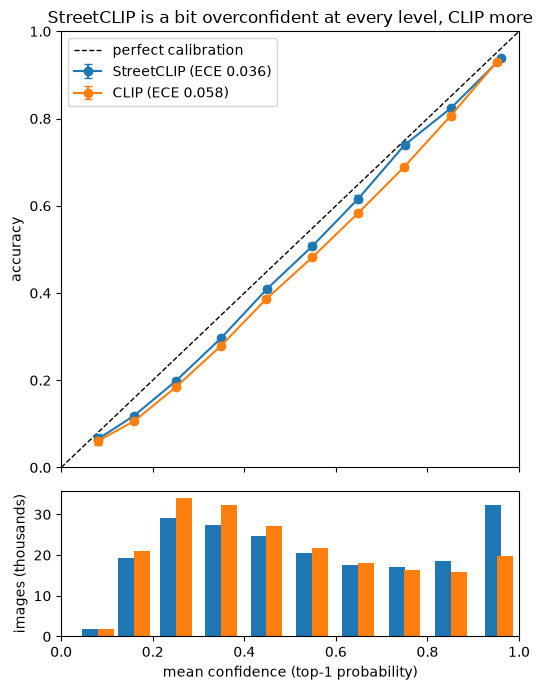

In [3]:
cal = {"StreetCLIP": q2.calibration_table(preds), "CLIP": q2.calibration_table(clip_preds)}
display(viz.show_table(cal["StreetCLIP"], {"n": "Images", "conf": "Mean confidence", "acc": "Accuracy"},
                       pct=["conf", "acc"], ci=("acc", "ci_low", "ci_high"), bar="n"))
q2.plot_reliability(cal, "StreetCLIP is a bit overconfident at every level, CLIP more");

### Q2.2 Where is the model confidently wrong?
- Per country: overconfidence = mean confidence - accuracy (> 0: overconfident)
- Confident: top-1 probability >= 0.8

In [4]:
sc_table = q2.country_table(preds, countries)
top_gap = sc_table[~sc_table.low_n].sort_values("gap", ascending=False).head(10)
display(viz.show_table(top_gap, {"name": "Country", "n": "Images", "acc": "Accuracy", "conf": "Mean confidence",
                                 "gap": "Overconfidence", "conf_wrong": "Confidently wrong"},
                       pct=["acc", "conf", "conf_wrong"], pts=["gap"], ci=("acc", "ci_low", "ci_high"), bar="gap",
                       index=False))
q2.plot_gap_map(sc_table).show()

Country,Images,Accuracy,95 % CI,Mean confidence,Overconfidence,Confidently wrong
Georgia,290,0.0 %,0.0 to 1.3 %,36.6 %,+36.6 pts,2.1 %
Kuwait,33,3.0 %,0.5 to 15.3 %,37.8 %,+34.8 pts,0.0 %
Estonia,274,15.3 %,11.5 to 20.1 %,49.0 %,+33.7 pts,11.3 %
Lithuania,131,2.3 %,0.8 to 6.5 %,35.1 %,+32.8 pts,0.0 %
Mali,"1,226",0.6 %,0.3 to 1.2 %,32.3 %,+31.7 pts,1.1 %
Swaziland,35,8.6 %,3.0 to 22.4 %,40.0 %,+31.4 pts,5.7 %
Zimbabwe,269,9.3 %,6.4 to 13.4 %,38.9 %,+29.6 pts,4.5 %
Yemen,497,6.4 %,4.6 to 8.9 %,35.3 %,+28.8 pts,1.2 %
Morocco,"1,266",9.4 %,7.9 to 11.1 %,38.2 %,+28.8 pts,1.3 %
Slovakia,150,8.0 %,4.6 to 13.5 %,36.3 %,+28.3 pts,0.7 %


In [5]:
conf_err = q2.confident_errors(preds, countries)
q2.plot_confident_errors(conf_err, "Two US pairs make up 40 % of all confident errors: US -> Georgia and US -> Canada").show()

#### The Georgia case
- "Georgia" is a country (GE) and a US state
- Prompt for GE: "A Street View photo in Georgia." (template and country name from the StreetCLIP paper)
- Which US states are guessed as the country Georgia?
- Does the original CLIP (same prompt, before fine-tuning) make the same error?
- Images below: random, not hand-picked; shown as the model sees them (center crop)

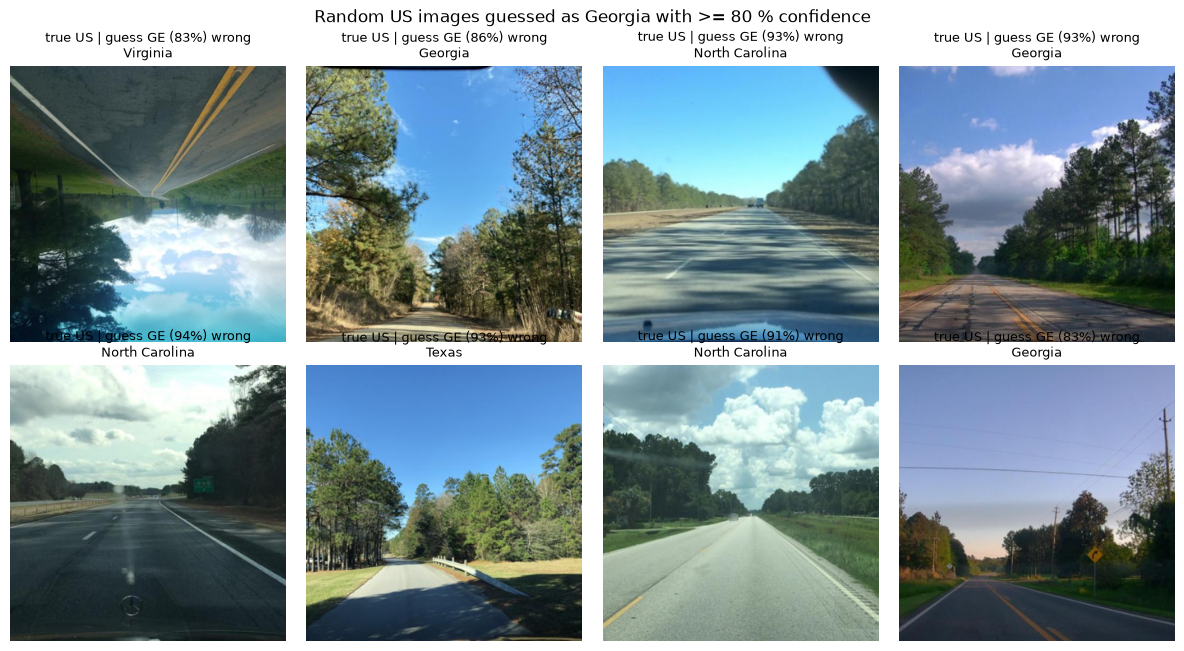

In [6]:
q2.plot_georgia_map(q2.georgia_states(preds),
                    "The country \"Georgia\" is guessed for the US South-East (89 % of the state of Georgia)").show()
viz.image_grid(dataset, q2.confident_examples(preds, "US", "GE"),
               "Random US images guessed as Georgia with >= 80 % confidence", note="region");

In [ ]:
ge_cmp = q2.georgia_compare({"CLIP": clip_preds, "StreetCLIP": preds})   # same prompt for both models
display(viz.show_table(ge_cmp, {"us_to_ge": "US images guessed Georgia", "us_share": "Share of US images",
                                "us_to_ge_conf": "... with >= 80 % confidence",
                                "ge_guess_us": "Georgia guesses that are US",
                                "ge_right": "Real Georgia right", "ge_n": "Real Georgia images"},
                       pct=["us_share", "ge_guess_us"]))

- Low precision: a label the model picks often, but wrongly
- Grey rows: country has no test images, so every guess of it is an error

In [7]:
pred_table = q2.predicted_table(preds, countries)
low_prec = pred_table[pred_table.n_pred >= 100].sort_values("precision").head(10)
display(viz.show_table(low_prec, {"name": "Guessed country", "n_pred": "Times guessed",
                                  "precision": "Right when guessed", "n_true": "Real test images"},
                       pct=["precision"], bar="n_pred", grey=low_prec.n_true == 0, index=False))

Guessed country,Times guessed,Right when guessed,Real test images
Georgia,"2,436",0.0 %,290
Gabon,740,0.0 %,7
Syria,793,0.0 %,1
Namibia,909,0.0 %,0
Guam,331,0.0 %,0
Andorra,196,0.0 %,0
San Marino,187,0.0 %,0
Nauru,286,0.0 %,0
Eritrea,169,0.0 %,13
Republic of the Congo,389,0.3 %,27


### Q2.3 Training coverage
- Paper's training list: uncertain evidence (says 101 countries, lists 92)
- Idea: countries in the Street View training should gain most from fine-tuning (CLIP -> StreetCLIP)
- Box plot: one dot = one country (hover for the name)

In [8]:
groups = q2.training_groups(sc_table).rename(index={True: "on the paper's list", False: "not on the list"})
display(viz.show_table(groups, {"countries": "Countries", "images": "Images", "macro_acc": "Macro accuracy",
                                "acc_ci": "95 % CI (+/-)", "macro_conf": "Macro confidence",
                                "mean_gap": "Mean overconfidence"},
                       pct=["macro_acc", "acc_ci", "macro_conf"], pts=["mean_gap"]))
gain = q2.gain_table(sc_table, q2.country_table(clip_preds, countries))
q2.plot_gain_by_group(gain, "Countries on the list gain a bit more, but the two groups overlap a lot").show()
q2.plot_gain(gain).show()

,Countries,Images,Macro accuracy,95 % CI (+/-),Macro confidence,Mean overconfidence
not on the list,85,"48,476",28.7 %,4.4 %,37.4 %,+8.8 pts
on the paper's list,86,"159,576",46.8 %,5.3 %,51.5 %,+4.7 pts


In [9]:
big = gain[~gain.low_n]
gain_cols = {"name": "Country", "n": "Images", "acc_clip": "CLIP", "acc": "StreetCLIP", "gain": "Gain"}
display(viz.show_table(big[~big.in_train_list].sort_values("gain", ascending=False).head(8), gain_cols,
                       pct=["acc_clip", "acc"], pts=["gain"], index=False))   # big gain, not in list
display(viz.show_table(big[big.in_train_list].sort_values("gain").head(8), gain_cols,
                       pct=["acc_clip", "acc"], pts=["gain"], index=False))   # in list, but no gain

Country,Images,CLIP,StreetCLIP,Gain
El Salvador,114,7.0 %,36.0 %,+28.9 pts
Uzbekistan,764,5.2 %,33.2 %,+28.0 pts
Niger,260,18.5 %,46.2 %,+27.7 pts
East Timor,213,3.8 %,28.2 %,+24.4 pts
Guinea-Bissau,90,28.9 %,52.2 %,+23.3 pts
Angola,"1,477",4.3 %,26.1 %,+21.8 pts
Ethiopia,"1,937",16.1 %,33.0 %,+16.9 pts
Saint Kitts and Nevis,60,48.3 %,63.3 %,+15.0 pts


Country,Images,CLIP,StreetCLIP,Gain
Finland,"2,280",91.8 %,62.6 %,-29.3 pts
Slovenia,73,37.0 %,12.3 %,-24.7 pts
Dominican Republic,165,27.3 %,4.8 %,-22.4 pts
Estonia,274,36.9 %,15.3 %,-21.5 pts
Uruguay,250,71.6 %,57.2 %,-14.4 pts
Uganda,837,39.3 %,25.0 %,-14.3 pts
Swaziland,35,22.9 %,8.6 %,-14.3 pts
Sri Lanka,571,65.5 %,52.2 %,-13.3 pts


### Q2 findings
- **Calibration:** StreetCLIP is a bit overconfident in every confidence bin (ECE 0.036). The original CLIP is more overconfident (0.058), so fine-tuning made the confidence more honest.
- **Confident errors:** 5,255 images are wrong with >= 80 % confidence. Two US pairs make up 40 % of them: US -> Georgia (1,126) and US -> Canada (995).
- **Georgia:** the model reads "Georgia" as the US state. 96 % of all "Georgia" guesses are US images, mostly from the South-East (89 % of the images from the state of Georgia). Real Georgia images are never right (0 of 290). This comes from pretraining, not from a bug in our setup: we use the paper's prompt ("A Street View photo in Georgia."), and the original CLIP already makes the same error (1,962 US images, 90 % of its "Georgia" guesses). Fine-tuning makes it stronger and more confident (634 -> 1,126 errors with >= 80 % confidence).
- **Training coverage:** countries on the paper's list are much more accurate (macro 46.8 % vs. 28.7 %). But most of this gap (13 of 18 points) already exists in the original CLIP (41.5 % vs. 28.1 %). Fine-tuning adds only a bit more on the list (mean gain +5.3 vs. +0.5 points, median +2.9 vs. +1.6), and the two groups overlap a lot. So the gain does not clearly confirm the list.

## Q4: Environment
Do accuracy and confidence vary with climate, land cover, distance to the sea, or urban vs. rural setting?
- Problem: environment and country are mixed up (a climate is mostly a few countries)
- **Expected from country mix**: accuracy we would get if only the country mattered
  (each image gets the accuracy of its country; big countries count more)
- **Within-country difference**: category accuracy minus its own country's accuracy, every country counts once
- Actual close to expected: the country mix explains it, not the environment

In [10]:
from pair_a import q4_environment as q4

env = q4.add_env_columns(preds)   # adds climate_group, urban (built-up or not), sea_bin

### Q4.1 Land cover
- First: who is in each class? Then: actual vs. expected accuracy

In [11]:
lc = q4.effect_table(env, "land_cover_name").drop(index="no data")
display(q4.show_effects(lc))
q4.plot_country_mix(env[env.land_cover_name != "no data"], "land_cover_name",
                    "Who is in each land cover class? Half of \"sparse vegetation\" is Australia").show()
q4.plot_expected(lc, "Land cover: built-up areas beat their country mix by 9 points; most classes stay within 3").show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
artificial surfaces,"10,392",136,60.5 %,59.6 to 61.4 %,51.9 %,+8.6 pts,+6.7 pts,73.0 %
bare soil,"10,745",81,33.4 %,32.5 to 34.3 %,35.6 %,-2.2 pts,-6.6 pts,36.4 %
cropland,"71,833",169,50.9 %,50.6 to 51.3 %,49.1 %,+1.9 pts,+1.6 pts,58.8 %
grassland,"22,977",152,49.4 %,48.7 to 50.0 %,49.8 %,-0.4 pts,-1.9 pts,36.4 %
"herbaceous, flooded","2,639",52,55.6 %,53.7 to 57.5 %,57.6 %,-2.0 pts,-0.6 pts,43.8 %
mangroves,191,29,42.9 %,36.1 to 50.0 %,44.2 %,-1.3 pts,,
shrubs,"19,622",110,44.3 %,43.6 to 45.0 %,45.3 %,-1.1 pts,-3.6 pts,39.1 %
snow and glaciers,91,8,75.8 %,66.1 to 83.5 %,59.4 %,+16.4 pts,,
sparse vegetation,"9,467",65,71.5 %,70.6 to 72.4 %,70.4 %,+1.1 pts,-4.6 pts,38.7 %
tree covered,"53,791",161,51.6 %,51.2 to 52.0 %,54.2 %,-2.6 pts,-5.2 pts,36.9 %


### Q4.2 Climate
- Köppen main groups (A tropical ... E polar)

In [12]:
groups_order = list(q4.CLIMATE_GROUPS.values())
cl = q4.effect_table(env, "climate_group")
display(q4.show_effects(cl))
q4.plot_country_mix(env, "climate_group", "Who is in each climate group?", order=groups_order).show()
q4.plot_expected(cl, "Climate: A to D are within 1.5 points of what the country mix predicts", order=groups_order).show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
A tropical,"52,436",99,38.2 %,37.8 to 38.6 %,39.6 %,-1.4 pts,-2.3 pts,29.1 %
B arid,"52,654",88,51.5 %,51.1 to 52.0 %,50.4 %,+1.1 pts,-0.8 pts,40.5 %
C temperate,"50,087",100,52.6 %,52.2 to 53.0 %,53.5 %,-0.8 pts,-0.6 pts,45.7 %
D continental,"48,590",60,61.2 %,60.8 to 61.6 %,59.8 %,+1.4 pts,-2.6 pts,45.7 %
E polar,"1,876",27,63.1 %,60.9 to 65.2 %,69.4 %,-6.3 pts,-14.8 pts,25.0 %


### Q4.3 Distance to the sea
- `dist_sea`: 0 = at the coast, 1 = far inland (capped; landlocked countries have median 1.0)
- OSV-5M does not document the unit, so we use fixed bins

In [13]:
sea = q4.effect_table(env, "sea_bin")
display(q4.show_effects(sea))
q4.plot_expected(sea, "Distance to the sea: small effects (coast -4 points, far inland +3), mostly in big countries",
                 order=q4.SEA_LABELS).show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
0-0.05 (coast),"24,629",144,50.5 %,49.9 to 51.1 %,54.9 %,-4.4 pts,-1.8 pts,35.8 %
0.05-0.25,"28,153",136,53.4 %,52.9 to 54.0 %,53.7 %,-0.2 pts,+0.6 pts,44.9 %
0.25-0.5,"17,831",116,51.9 %,51.1 to 52.6 %,53.8 %,-1.9 pts,-0.1 pts,51.1 %
0.5-0.9,"28,892",115,49.6 %,49.0 to 50.2 %,51.1 %,-1.5 pts,-0.9 pts,44.3 %
0.9-0.99,"25,827",92,51.1 %,50.5 to 51.7 %,51.9 %,-0.8 pts,-0.8 pts,52.5 %
0.99-1 (inland),"82,982",90,50.1 %,49.7 to 50.4 %,47.5 %,+2.6 pts,-0.0 pts,47.4 %


### Q4.4 Urban vs. rural
- No urban column in OSV-5M. Proxy: land cover "artificial surfaces" (built-up area)
- `road_index` is not usable: it has only one value per country
- Check: one vote per camera sequence, so a long drive does not count many times

In [14]:
ur = q4.effect_table(env, "urban")
ur_seq = q4.effect_table(q4.per_sequence(env, "urban"), "urban")
display(q4.show_effects(pd.concat({"per image": ur, "per sequence": ur_seq})))

- Per country (>= 20 images in both groups); grey rows: fewer than 10 built-up sequences (weak evidence, not on the map)

Country,Built-up images,Built-up sequences,Accuracy built-up,Accuracy other,Difference
Peru,39,14,12.8 %,48.3 %,-35.5 pts
Botswana,26,14,50.0 %,82.2 %,-32.2 pts
Papua New Guinea,26,12,7.7 %,36.2 %,-28.6 pts
Angola,36,14,8.3 %,26.6 %,-18.2 pts
Algeria,148,64,18.9 %,32.7 %,-13.8 pts


Country,Built-up images,Built-up sequences,Accuracy built-up,Accuracy other,Difference
Egypt,47,37,55.3 %,20.8 %,+34.5 pts
Senegal,25,16,44.0 %,6.8 %,+37.2 pts
China,762,301,84.4 %,43.9 %,+40.5 pts
Afghanistan,100,20,97.0 %,35.2 %,+61.8 pts
Libya,54,7,92.6 %,24.4 %,+68.1 pts


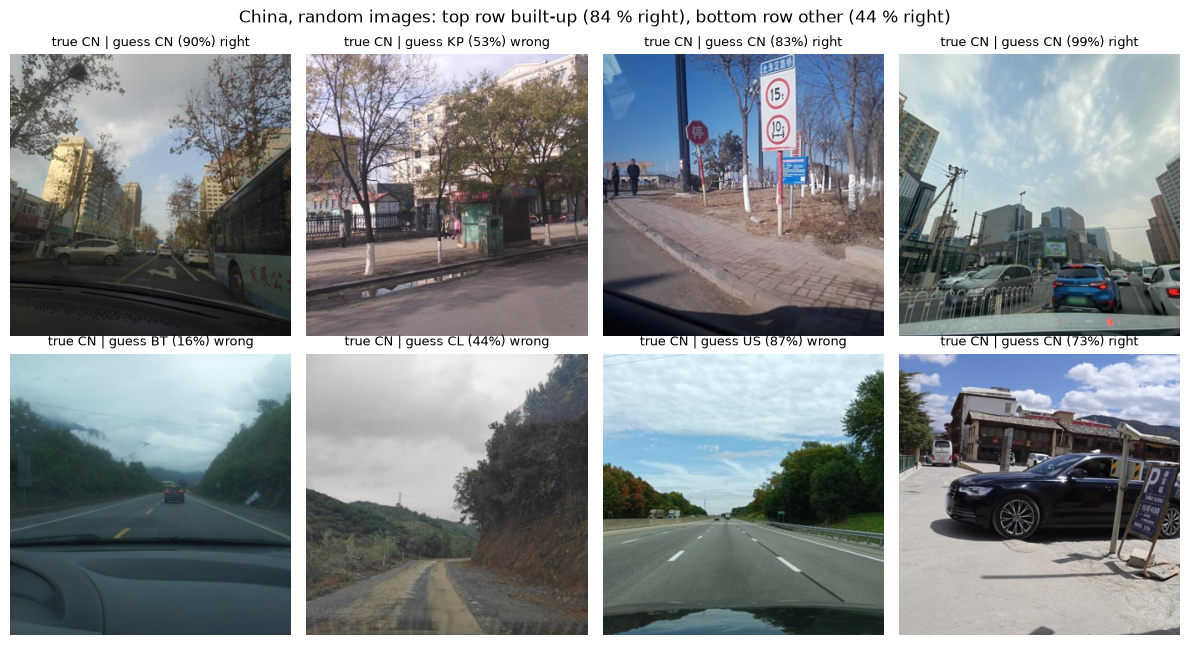

In [15]:
urb = q4.urban_table(env, mapper.table)
urb_cols = {"name": "Country", "size_urban": "Built-up images", "seq_urban": "Built-up sequences",
            "mean_urban": "Accuracy built-up", "mean_rural": "Accuracy other", "diff": "Difference"}
for part in [urb.head(5), urb.tail(5)]:   # worst and best for built-up areas
    display(viz.show_table(part, urb_cols, pct=["mean_urban", "mean_rural"], pts=["diff"],
                           grey=part.seq_urban < q4.MIN_SEQ, index=False))
q4.plot_urban_map(urb).show()
viz.image_grid(dataset, q4.urban_examples(env, "CN"),
               "China, random images: top row built-up (84 % right), bottom row other (44 % right)");

### Q4 findings
- **Climate:** raw accuracy differs a lot (A tropical 38 %, D continental 61 %), but A to D are within 1.5 points of what their country mix predicts. Inside countries the difference is also small (within 3 points). Only E polar is lower (-6 points vs. expected, -15 within-country), but with few images and only 12 countries. So the climate effect is mostly the country mix.
- **Land cover:** most classes stay within 3 points of their country mix. "sparse vegetation" looks easy (72 %) only because half of it is Australia. Clear exception: built-up areas (+8.6 points vs. expected, +6.7 within-country). Water bodies are worse (-5.5 / -4.0).
- **Bare soil:** looks very hard (33 %), but its country mix already predicts 36 %. Within-country it is -6.6 points, so smaller countries drop more there.
- **Distance to the sea:** small effects. The coast is worse (-4.4 points vs. expected, -4.2 with one vote per sequence), far inland is a bit better (+2.6). Mostly big countries: US coast images are 38 % right, the US overall 63 %. With every country counted once the effect is small (-1.8 +/- 2.3 points).
- **Urban vs. rural:** built-up areas are better than the country average in 73 % of 74 countries (+6.7 points). This also holds with one vote per camera sequence (+8.3 points, 52 countries). Very large values for single countries (Libya, Afghanistan) come from only a few sequences.
- **Confidence:** moves with accuracy, but less (built-up: confidence +4.6 points, accuracy +6.7). Bare soil has the largest gap between confidence and accuracy (0.118, overconfident).
- `road_index` has one value per country, so it cannot measure urban vs. rural.
- Open questions: does the urban advantage come from text and signs (the Q3 masking can test this)? Why are US coast images so hard?